In [1]:
import numpy as np
import os
import utils
import matplotlib.pyplot as plt
import dijkstra
import a_star
import bfs
import greedy
from matplotlib.animation import FuncAnimation, PillowWriter, ArtistAnimation

def test_algorithm(planner, start, goal, ax, grid_map, title, fig):
  
  # Check if the planner is a costmap planner( inherits from Dijkstra)
  if issubclass(type(planner), dijkstra.Dijkstra):
    utils.plot_costmap(planner.costmap, title, ax)
  else:
    utils.plot_gridmap(grid_map, title, ax)
  path, frames = planner.plan(start, goal, ax, fig)
  return path, frames

def compare_motion(planner_class, start, goal, grid_map):
  fig, axes = plt.subplots(1, 2, figsize=(12,6))
  fig.suptitle(f'Comparing 4 and 8 connectivity for {planner_class.__name__}')
  ax = axes[0]
  ax2 = axes[1]
  planner1 = planner_class(grid_map, utils.Movements4Connectivity(), plot_enabled=True)
  planner2 = planner_class(grid_map, utils.Movements8Connectivity(), plot_enabled=True)
  path1, frames1 = test_algorithm(planner1, start, goal, ax, grid_map, 'planner 4', fig)
  path2, frames2 = test_algorithm(planner2, start, goal, ax2, grid_map, 'planner 8', fig)
  
  frames = []
  for i in range(max(len(frames1), len(frames2))):
    frame = frames1[min(len(frames1) -1, i)] + frames2[min(len(frames2) -1, i)]
    frames.append(frame)
  ani = ArtistAnimation(fig, frames, interval=1, blit=True, repeat_delay=1000)
  ani.save(f'images/{planner_class.__name__}_motion.gif', writer='ffmpeg', fps=10)
  # plt.show()

def compare_algorithms(start, goal, grid_map, movements):
  fig, axes = plt.subplots(2, 2, figsize=(12,12))
  fig.suptitle(f'Comparing algorithms on the same map with {movements.__class__.__name__}')
  algorithms = [bfs.BFS, dijkstra.Dijkstra, greedy.Greedy, a_star.AStar]
  frames_lists = []
  for i, planner_class in enumerate(algorithms):
    ax = axes[i//axes.shape[1], i%axes.shape[1]]
    planner = planner_class(grid_map, movements, plot_enabled=True)
    _, frames = test_algorithm(planner, start, goal, ax, grid_map, planner_class.__name__, fig)
    frames_lists.append(frames)

  frames = []
  for i in range(max([len(frames) for frames in frames_lists])):
    frame = []
    for frames_i in frames_lists:
      frame += frames_i[min(len(frames_i) -1, i)]
    frames.append(frame)
  ani = ArtistAnimation(fig, frames, interval=1, blit=True, repeat_delay=1000)
  ani.save(f'images/{movements.__class__.__name__}_algorithms.gif', writer='ffmpeg', fps=10)
  # plt.show()


In [2]:
relative_path = "../2D_maps/map1.png"
print("Testing dijkstra on map1.png")
print("current directory: ", os.getcwd())
curr_dir = os.getcwd()
                            
map_path = os.path.join(curr_dir, relative_path)

xy_reso = 3
_, grid_map = utils.get_map(map_path, xy_reso)
start = np.array([20, 0])
goal = np.array([0, 20])


Testing dijkstra on map1.png
current directory:  /workspaces/vscode_ros2_workspace/src/lecture_notebooks/planning_control_methodss/Path_Planners
Map size: (64, 64)
Grid Map size: (22, 22)


MovieWriter ffmpeg unavailable; using Pillow instead.


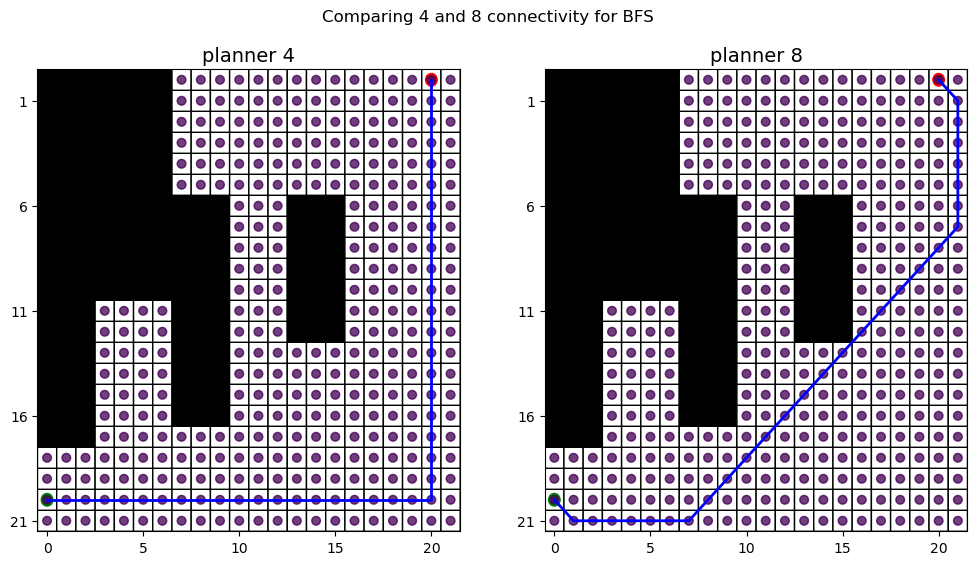

In [3]:
compare_motion(bfs.BFS, start, goal, grid_map)

MovieWriter ffmpeg unavailable; using Pillow instead.


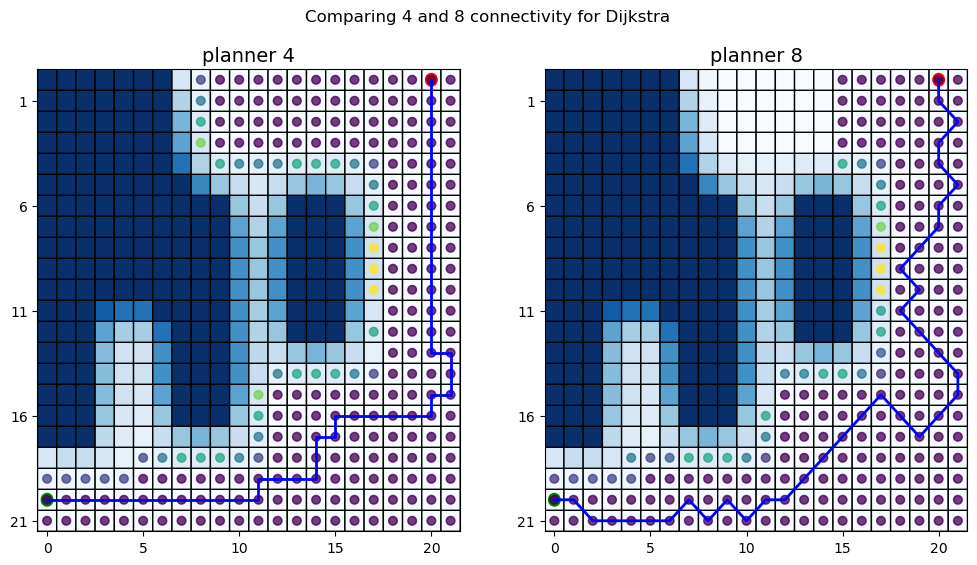

In [4]:
compare_motion(dijkstra.Dijkstra, start, goal, grid_map)

MovieWriter ffmpeg unavailable; using Pillow instead.


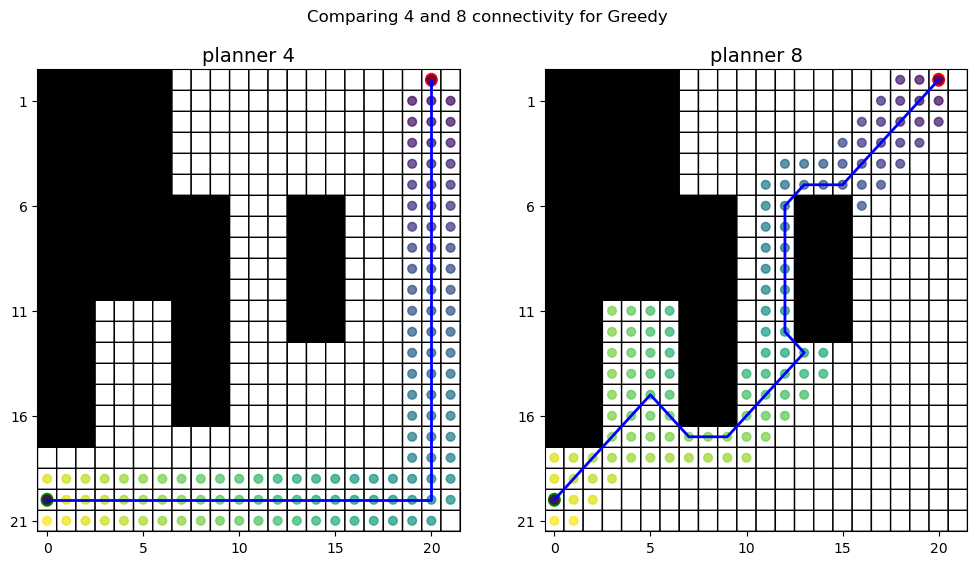

In [5]:
compare_motion(greedy.Greedy, start, goal, grid_map)

MovieWriter ffmpeg unavailable; using Pillow instead.


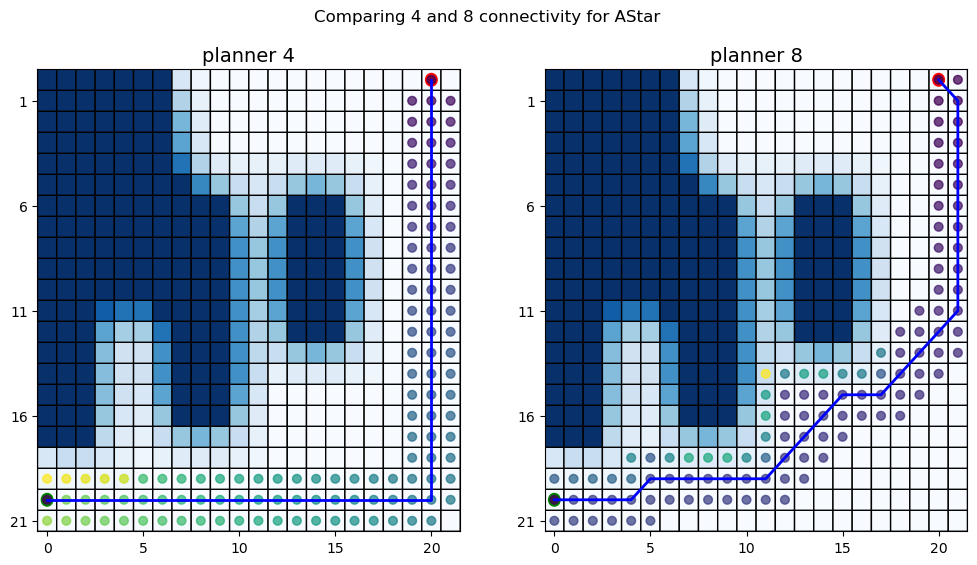

In [6]:
compare_motion(a_star.AStar, start, goal, grid_map)

MovieWriter ffmpeg unavailable; using Pillow instead.


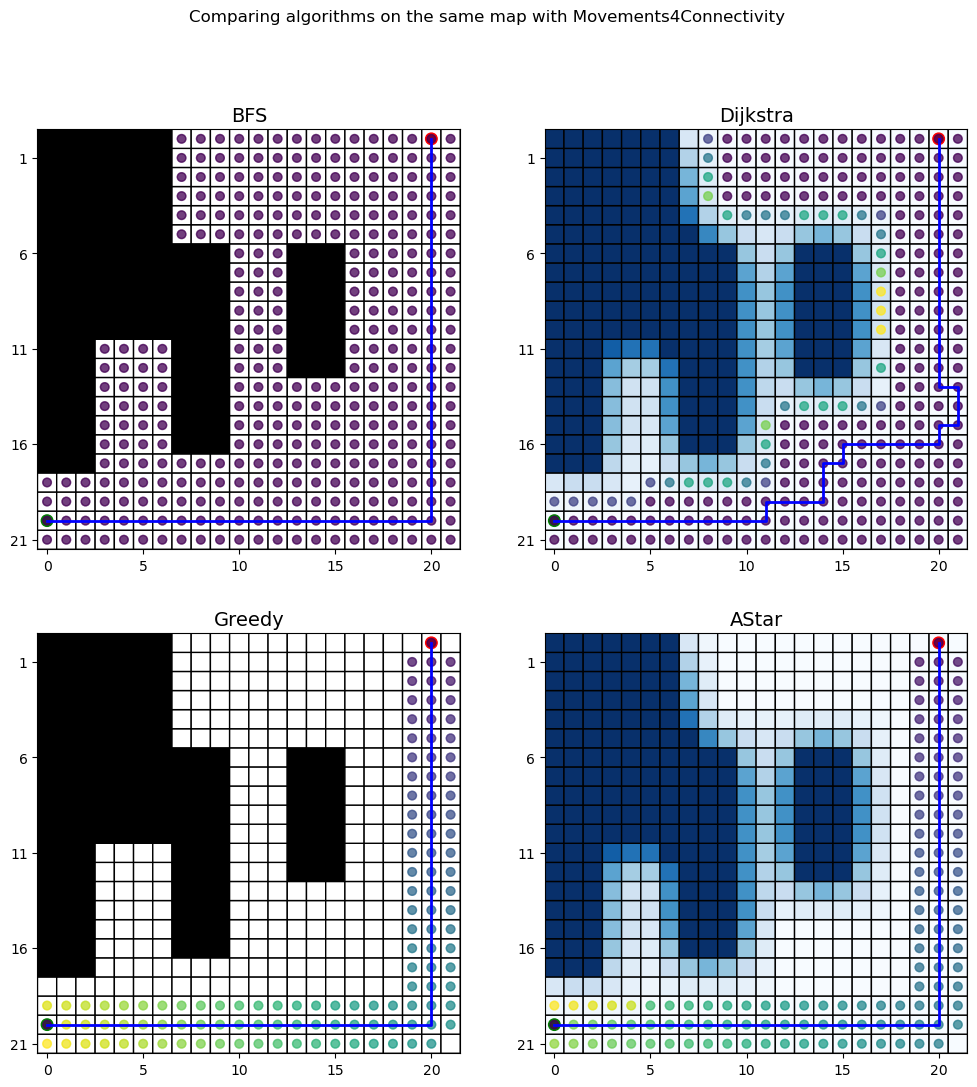

In [7]:
compare_algorithms(start, goal, grid_map, utils.Movements4Connectivity())

MovieWriter ffmpeg unavailable; using Pillow instead.


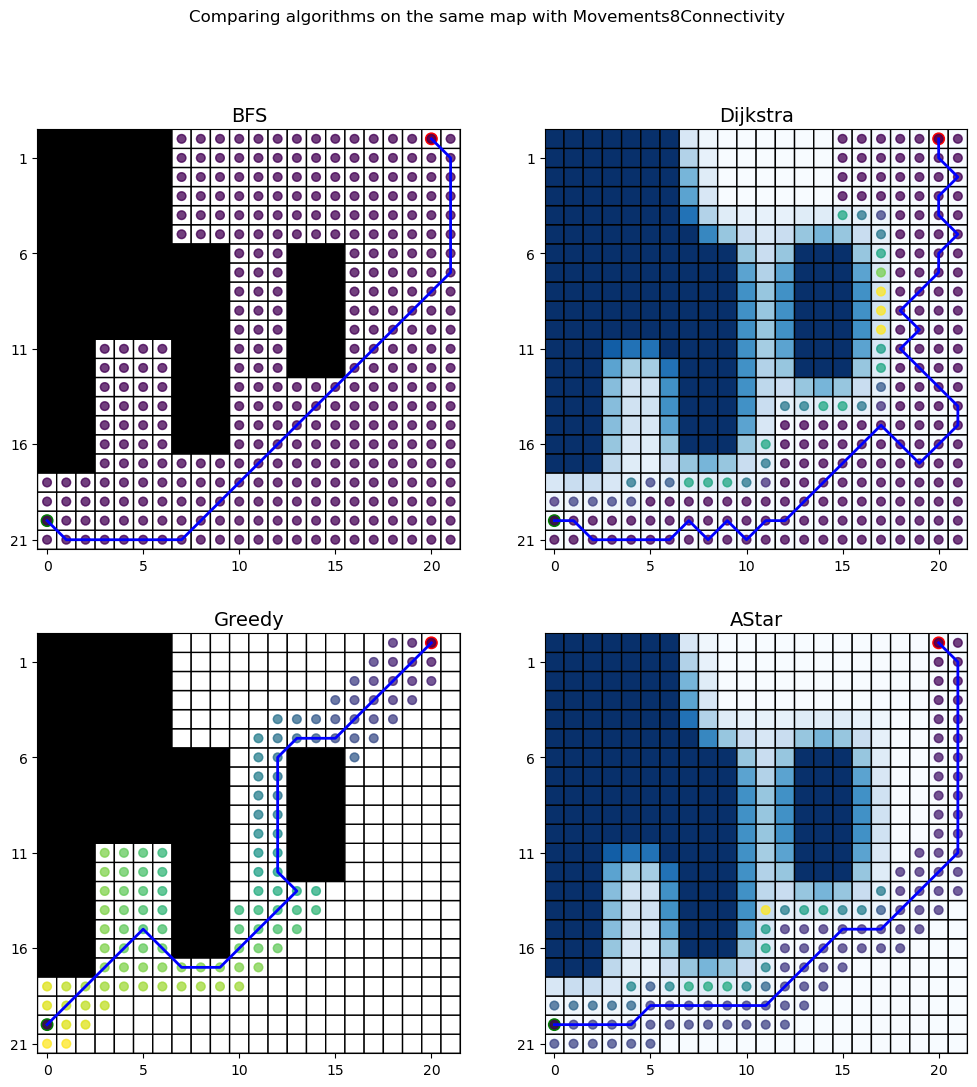

In [8]:
compare_algorithms(start, goal, grid_map, utils.Movements8Connectivity())